# One-class autoencoder on the T = 32 benign windows of all 8 scenario folders

The professor's one-class baseline: a small 1D-conv autoencoder (14 × 32 in, z = 16) trained on **genuine (benign)
windows only** from `src/data/encoder_input/all/T32_benign/`. The train / val / test split (80 / 10 / 10 by sender
vehicle over all 8 folders) is fixed on disk; train and val hold benign windows only. Val drives early stopping, the LR
schedule and the alarm thresholds. The test splits are opened only in section 5: the benign test split and the attack
windows of the same test vehicles (`test_gridsybil`, `test_datareplay`, `test_dosrandom`, `test_dosdisruptive`).

Two label-free scores per window: the reconstruction error (masked MSE over real rows), and the **Mahalanobis
distance** of z to a Gaussian fitted on the benign train z. Each is also aggregated per **track** (one link = one
receiver hearing one sender pseudonym): max and mean over the track's windows.

This notebook runs from the repo root, imports the package classes and reads the run folder written by
`npm run aeb32:train`. Sections: 1 input, 2 model, 3 training record, 4 reconstruction on val, 5 test, 6 context,
7 analysis.

Setup: repo-root check, package imports, the run folder (the newest `runs/*/summary.json`).

In [1]:
import json
from pathlib import Path

assert Path("task/autoencoder_benign_t32/config.py").is_file(), "run this notebook from the repo root"

from task.autoencoder_benign_t32.config import EVAL_SPLITS, TOTAL_PARAMS, AutoencoderConfig
from task.autoencoder_benign_t32.data import WindowDataset
from task.autoencoder_benign_t32.model import ConvAutoencoder, count_params
from task.autoencoder_benign_t32.scoring import Mahalanobis, TrackScores, quantile_thresholds
from task.autoencoder_benign_t32.trainer import Trainer

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, roc_auc_score

settings = AutoencoderConfig()
runs = sorted(Path(settings.runs_dir).glob("*/summary.json"), key=lambda p: p.stat().st_mtime)
assert runs, "no finished run: npm run aeb32:train"
RUN = runs[-1].parent
META = json.loads((Path(settings.data_dir) / "metadata.json").read_text())
FEATURES = META["features"]
ATTACKS = {"test_gridsybil": "GridSybil", "test_datareplay": "DataReplay", "test_dosrandom": "DoSRandom",
           "test_dosdisruptive": "DoSDisruptive"}
print("run folder:", RUN)
print("data:", settings.data_dir)

run folder: task/autoencoder_benign_t32/runs/seed0
data: src/data/encoder_input/all/T32_benign


## 1. Input

Seven splits on disk. Train / val / test hold the **benign** windows of disjoint sender-vehicle sets (80 / 10 / 10 by
vehicle key `<group>:<vehicle>`, stratified by group and vehicle class, seed 0); the four `test_<attack>` splits hold the
attack windows of the **test** vehicles (attack windows of train / val vehicles were dropped when the input was built).
Counts below come from `metadata.json`; the test splits themselves are not opened before section 5.

In [2]:
order = ["train", "val", "test", *ATTACKS]
cbs = pd.DataFrame(META["counts_by_split"]).T.loc[order]
cbs = cbs[["windows", "messages", "links", "vehicles", "padding_share", "windows_1_3", "share_1_3"]]
for c in ("windows", "messages", "links", "vehicles", "windows_1_3"):
    cbs[c] = cbs[c].astype(int)
cbs.columns = ["windows", "messages", "links (tracks)", "sender vehicles", "padding share", "1-3-row windows",
               "1-3-row share"]
cbs

,windows,messages,links (tracks),sender vehicles,padding share,1-3-row windows,1-3-row share
train,502773,8365846,401986,4206,0.4800,68836,0.1369
val,65313,1083336,52108,524,0.4817,9102,0.1394
test,60142,996650,48188,525,0.4821,8369,0.1392
test_gridsybil,28087,405921,23166,172,0.5484,5722,0.2037
test_datareplay,76283,114133,76283,173,0.9532,72400,0.9491
test_dosrandom,199834,227491,199834,173,0.9644,199311,0.9974
test_dosdisruptive,199826,227491,199826,173,0.9644,199302,0.9974


Split diagram: windows per split (log scale), with the sender vehicles behind each split.

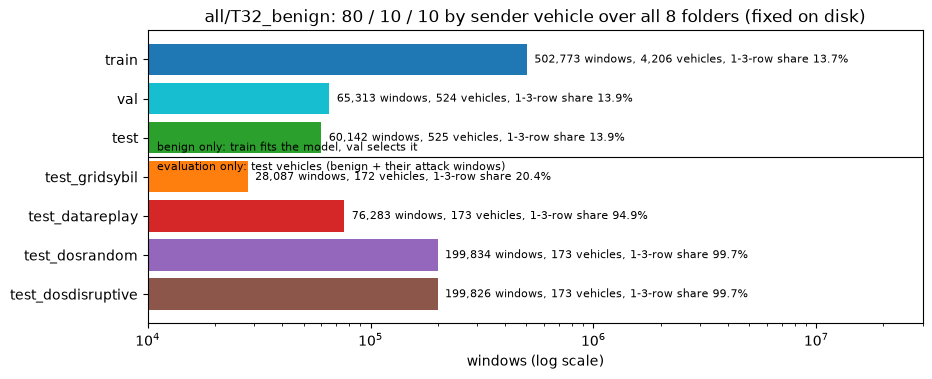

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
colors = ["tab:blue", "tab:cyan", "tab:green", "tab:orange", "tab:red", "tab:purple", "tab:brown"]
for y, name in enumerate(reversed(order)):
    w = int(cbs.loc[name, "windows"])
    ax.barh(y, w, color=colors[order.index(name)])
    ax.text(w * 1.08, y, f"{w:,} windows, {int(cbs.loc[name, 'sender vehicles']):,} vehicles, "
            f"1-3-row share {cbs.loc[name, '1-3-row share']:.1%}", va="center", fontsize=8)
ax.set_yticks(range(len(order)), list(reversed(order))); ax.set_xscale("log"); ax.set_xlim(1e4, 3e7)
ax.axhline(3.5, color="black", lw=0.8)
ax.text(1.1e4, 3.6, "benign only: train fits the model, val selects it", fontsize=8, va="bottom")
ax.text(1.1e4, 3.4, "evaluation only: test vehicles (benign + their attack windows)", fontsize=8, va="top")
ax.set_xlabel("windows (log scale)")
ax.set_title("all/T32_benign: 80 / 10 / 10 by sender vehicle over all 8 folders (fixed on disk)")
plt.show()

Load the two splits used for fitting (from the decoded-shard cache when present) and check them.

In [4]:
splits = {name: WindowDataset.load(settings.data_dir, name, settings.workers, cache_dir=settings.cache_dir)
          for name in ("train", "val")}
train, val = splits["train"], splits["val"]
assert not (set(train.vehicles) & set(val.vehicles)), "a sender vehicle in train and val"
for d in (train, val):
    assert (d.info["label"].astype(int) == 0).all() and (d.info["is_attack"].astype(int) == 0).all()
    assert len(d) == META["counts_by_split"][d.split]["windows"]
print("train and val: benign only, no sender vehicle in both, window counts equal metadata")
pd.DataFrame({d.split: {"windows": len(d), "tracks": len(set(d.tracks)), "sender vehicles": len(set(d.vehicles)),
                        "scenario folders": len(set(d.info["scenario"]))} for d in (train, val)}).T

train and val: benign only, no sender vehicle in both, window counts equal metadata


,windows,tracks,sender vehicles,scenario folders
train,502773,401986,4206,8
val,65313,52108,524,8


Shape: each window is up to 32 messages (1 Hz) of one link × 13 normalised features, padded to 32 rows; padding rows
are zero and a prefix mask marks the real rows. The model gets the 13 features plus the mask as a 14th channel:
**14 × 32** per window. Links longer than 32 messages are cut into consecutive non-overlapping crops (the last one may
be short).

window x: (32, 13) + mask: (32,) -> model input: (14, 32)


,min,median,mean,max,share = 32,share 1-3,padding share
split,,,,,,,
train,1,15.0,16.64,32,0.210,0.137,0.480
val,1,15.0,16.59,32,0.212,0.139,0.482


padding over all 7 splits: 0.685; 1-3-row share over all 7 splits: 0.497


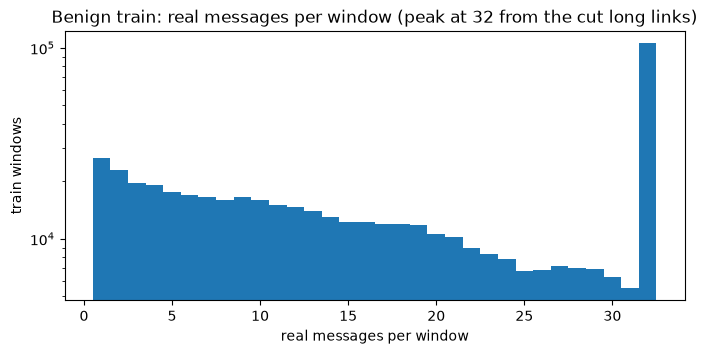

In [5]:
print("window x:", train.x.shape[1:], "+ mask:", train.mask.shape[1:], "-> model input:",
      (settings.n_features + 1, settings.seq_len))
rows = []
for name, d in splits.items():
    n = d.n_messages
    rows.append({"split": name, "min": n.min(), "median": np.median(n), "mean": round(n.mean(), 2), "max": n.max(),
                 "share = 32": round(float((n == 32).mean()), 3), "share 1-3": round(float((n <= 3).mean()), 3),
                 "padding share": round(1 - d.mask.mean(), 3)})
display(pd.DataFrame(rows).set_index("split"))
print(f"padding over all 7 splits: {META['padding']['overall']:.3f}; "
      f"1-3-row share over all 7 splits: {META['padding']['share_1_3_overall']:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train.n_messages, bins=np.arange(1, 34) - 0.5, color="tab:blue")
ax.set_xlabel("real messages per window"); ax.set_ylabel("train windows"); ax.set_yscale("log")
ax.set_title("Benign train: real messages per window (peak at 32 from the cut long links)")
plt.show()

Per-feature statistics over the **real** train rows (normalised with the benign train mean / std, so ≈ 0 / 1).

In [6]:
real = train.x[train.mask]  # (real rows, 13)
pd.DataFrame({"mean": real.mean(0), "std": real.std(0), "min": real.min(0), "max": real.max(0)},
             index=FEATURES).round(3)

,mean,std,min,max
claimed_pos_x,-0.0,1.000,-1.156,2.359000
claimed_pos_y,0.0,0.991,-2.014,2.368000
rx_pos_x,-0.0,1.000,-1.156,2.359000
rx_pos_y,0.0,0.991,-2.014,2.367000
claimed_vel_x,0.0,0.993,-2.546,2.553000
claimed_vel_y,0.0,0.998,-2.296,2.232000
rx_vel_x,0.0,0.993,-2.630,2.570000
rx_vel_y,-0.0,0.998,-2.331,2.227000
claimed_acl_x,-0.0,0.994,-5.179,5.180000
claimed_acl_y,-0.0,0.994,-3.719,3.749000


One train window: the first full (32-row) window of the train split, as a heat map of its 13 features.

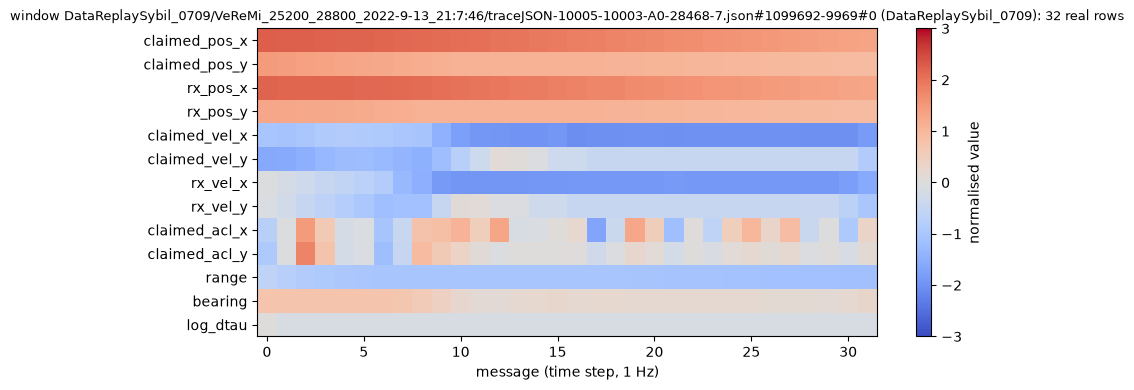

In [7]:
i = int(np.flatnonzero(train.n_messages == 32)[0])
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(train.x[i].T, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
ax.set_yticks(range(len(FEATURES)), FEATURES); ax.set_xlabel("message (time step, 1 Hz)")
ax.set_title(f"window {train.ids[i]} ({train.info['scenario'][i]}): {train.n_messages[i]} real rows", fontsize=9)
fig.colorbar(im, ax=ax, label="normalised value")
plt.show()

## 2. Model

Layers with their output shapes for one batch of 2 windows, and the trainable parameter count (asserted against the
package constant).

In [8]:
model = ConvAutoencoder(settings)
x0, m0 = torch.zeros(2, settings.seq_len, settings.n_features), torch.ones(2, settings.seq_len, dtype=torch.bool)
table = []
layer_types = (torch.nn.Conv1d, torch.nn.ConvTranspose1d, torch.nn.Linear, torch.nn.BatchNorm1d)
hooks = [mod.register_forward_hook(lambda mod, inp, out, name=name: table.append(
    (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))))
    for name, mod in model.named_modules() if isinstance(mod, layer_types)]
model.eval()
with torch.no_grad():
    recon0, z0 = model(x0, m0)
for h in hooks:
    h.remove()
display(pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"]))
params = count_params(model)
assert params == TOTAL_PARAMS, (params, TOTAL_PARAMS)
print("reconstruction:", tuple(recon0.shape[1:]), " z:", tuple(z0.shape[1:]))
print(f"trainable parameters: {params:,} (= TOTAL_PARAMS)")

,layer,type,output (per window),params
0,encoder_conv.0,Conv1d,"(32, 32)",1376
1,encoder_conv.1,BatchNorm1d,"(32, 32)",64
2,encoder_conv.3,Conv1d,"(64, 16)",6208
3,encoder_conv.4,BatchNorm1d,"(64, 16)",128
4,encoder_conv.6,Conv1d,"(64, 8)",12352
5,encoder_conv.7,BatchNorm1d,"(64, 8)",128
6,to_z,Linear,"(16,)",8208
7,from_z,Linear,"(512,)",8704
8,decoder_conv.1,ConvTranspose1d,"(64, 16)",16448
9,decoder_conv.2,BatchNorm1d,"(64, 16)",128


reconstruction: (32, 13)  z: (16,)
trainable parameters: 63,293 (= TOTAL_PARAMS)


## 3. Training record

What `task.autoencoder_benign_t32.train` wrote: the summary (thresholds shown in section 5), the per-epoch history
(train vs validation masked MSE, best epoch, LR drops; then the gradient L2 norm, mean and max over the epoch's
batches, before clipping, and the LR) and log lines.

{
  "run_id": "seed0",
  "params": 63293,
  "best_epoch": 151,
  "best_val_loss": 0.10502999553267371,
  "epochs_run": 161,
  "stop_reason": "early_stopping",
  "lr_changes": [
    {
      "after_epoch": 98,
      "from": 0.001,
      "to": 0.0005
    },
    {
      "after_epoch": 107,
      "from": 0.0005,
      "to": 0.00025
    },
    {
      "after_epoch": 121,
      "from": 0.00025,
      "to": 0.000125
    },
    {
      "after_epoch": 130,
      "from": 0.000125,
      "to": 6.25e-05
    },
    {
      "after_epoch": 138,
      "from": 6.25e-05,
      "to": 3.125e-05
    },
    {
      "after_epoch": 148,
      "from": 3.125e-05,
      "to": 1.5625e-05
    },
    {
      "after_epoch": 157,
      "from": 1.5625e-05,
      "to": 7.8125e-06
    }
  ],
  "train_seconds": 1165.2,
  "train_windows": 502773,
  "val_windows": 65313,
  "train_tracks": 401986,
  "val_tracks": 52108,
  "train_vehicles": 4206,
  "val_vehicles": 524,
  "mahalanobis": {
    "cond": 30.1503837996538,
    "shr

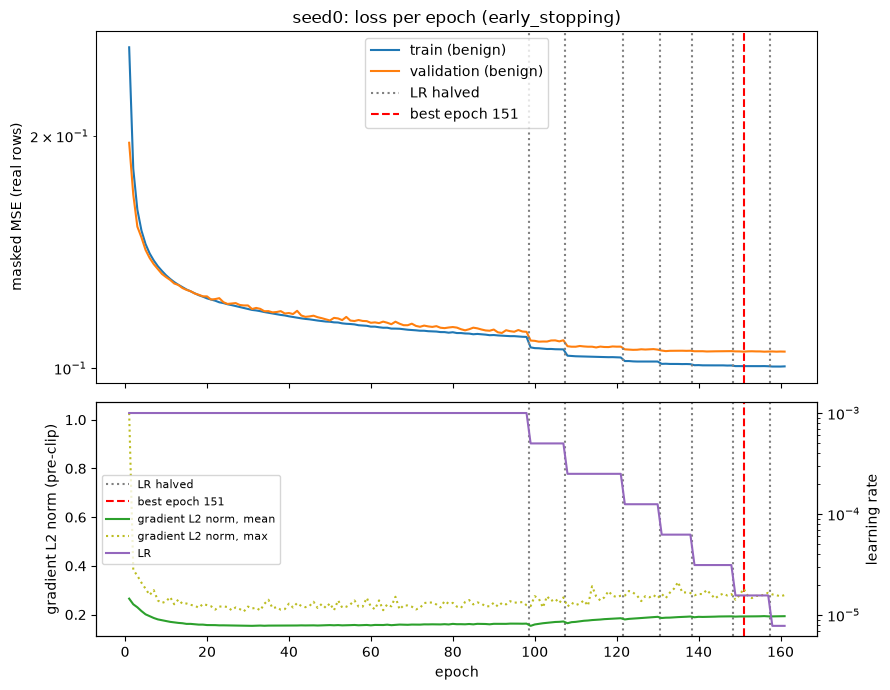

,train_loss,val_loss,lr,grad_norm_mean,grad_norm_max,seconds
epoch,,,,,,
1,0.26052,0.19593,0.00100,0.26547,1.02764,8.27
2,0.18129,0.16788,0.00100,0.24224,0.38397,6.76
151,0.10060,0.10503,0.00002,0.19227,0.30607,7.23
161,0.10051,0.10504,0.00001,0.19340,0.28025,7.71


2026-10-29T21:10:36 train 502,773 / val 65,313 benign windows (1s to load), shape (32, 13) + mask; vehicles 4,206 / 524; tracks 401,986 / 52,108
2026-10-29T21:10:36 padding share train 0.480 / val 0.482, real messages per window median 15, 1-3-row windows train 0.137 / val 0.139
2026-10-29T21:10:36 ConvAutoencoder: 63,293 trainable parameters, input 14 x 32, z 16
2026-10-29T21:10:37 fit: 502,773 benign windows, val: 65,313 benign windows, batch 256, device mps, grad_clip 1, early stopping on val loss (min_delta 0.0001 relative, patience 10)
2026-10-29T21:10:45 epoch   1  train 0.26052  val 0.19593  lr 1.00e-03  grad_norm 0.2655/1.0276  8.3s *best
2026-10-29T21:10:52 epoch   2  train 0.18129  val 0.16788  lr 1.00e-03  grad_norm 0.2422/0.3840  6.8s *best
...
2026-10-29T21:27:43 epoch 142  train 0.10081  val 0.10508  lr 3.13e-05  grad_norm 0.1906/0.3012  7.1s *best
2026-10-29T21:28:50 epoch 151  train 0.10060  val 0.10503  lr 1.56e-05  grad_norm 0.1923/0.3061  7.2s *best
...
2026-10-29T21

In [9]:
summary = json.loads((RUN / "summary.json").read_text())
print(json.dumps({k: v for k, v in summary.items() if k != "thresholds"}, indent=2))
history = pd.read_json(RUN / "history.jsonl", lines=True)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=(3, 2))
ax.plot(history.epoch, history.train_loss, label="train (benign)")
ax.plot(history.epoch, history.val_loss, label="validation (benign)")
for a in (ax, ax2):
    for k, c in enumerate(summary["lr_changes"]):
        a.axvline(c["after_epoch"] + 0.5, color="grey", ls=":", label="LR halved" if k == 0 else None)
    a.axvline(summary["best_epoch"], color="red", ls="--", label=f"best epoch {summary['best_epoch']}")
ax.set_yscale("log"); ax.set_ylabel("masked MSE (real rows)"); ax.legend()
ax.set_title(f"{RUN.name}: loss per epoch ({summary['stop_reason']})")
ax2.plot(history.epoch, history.grad_norm_mean, color="tab:green", label="gradient L2 norm, mean")
ax2.plot(history.epoch, history.grad_norm_max, color="tab:olive", ls=":", label="gradient L2 norm, max")
ax2.set_ylabel("gradient L2 norm (pre-clip)"); ax2.set_xlabel("epoch")
lr_ax = ax2.twinx(); lr_ax.plot(history.epoch, history.lr, color="tab:purple", label="LR"); lr_ax.set_yscale("log")
lr_ax.set_ylabel("learning rate")
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = lr_ax.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, fontsize=8)
fig.tight_layout(); plt.show()
display(history.iloc[[0, 1, summary["best_epoch"] - 1, len(history) - 1]].set_index("epoch").round(5))
log = (RUN / "train.log").read_text().splitlines()
print("\n".join(log[:6] + ["..."] + [l for l in log if "*best" in l][-2:] + ["..."] + log[-4:-1]))

## 4. Reconstruction on val

Load `best.pt` and rebuild the benign val windows: three full val windows, input vs reconstruction for three features;
then the mean reconstruction error per feature over val.

val windows 65,313; mean window error 0.1071; pooled over real rows 0.1050 (run's best val loss 0.1050)


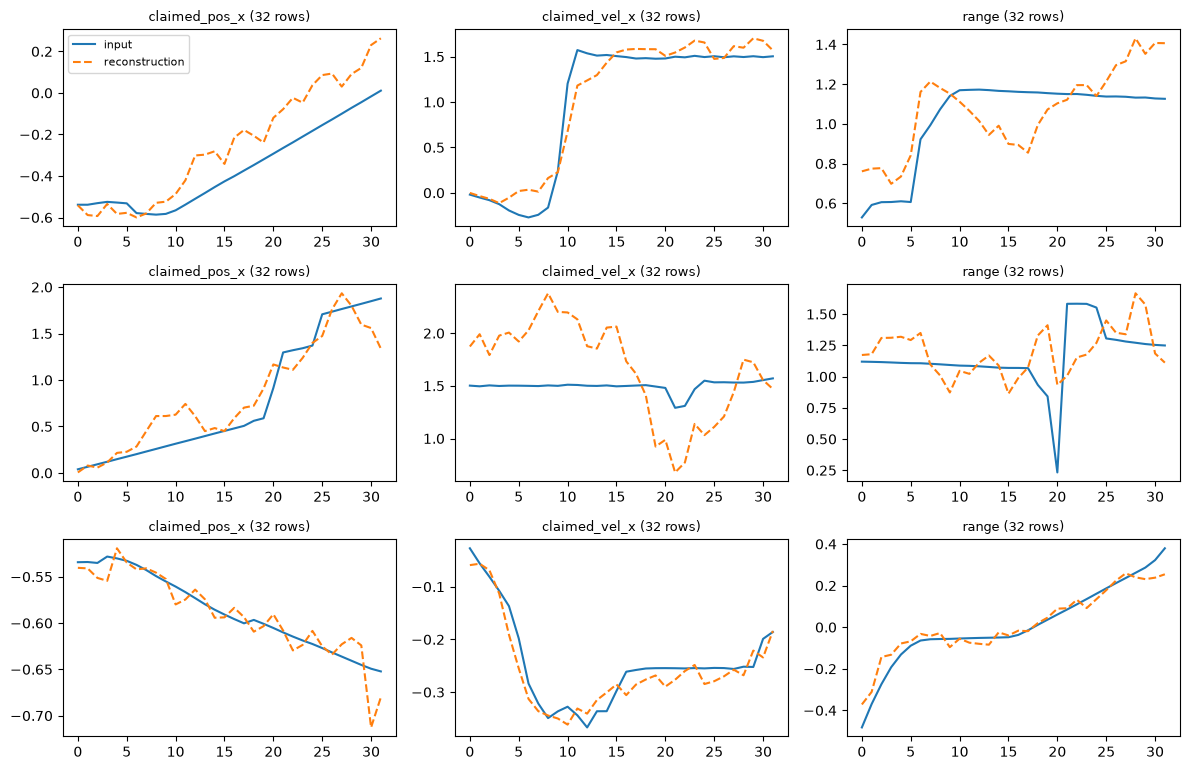

,val MSE
claimed_acl_x,0.3674
claimed_acl_y,0.3346
log_dtau,0.1230
rx_vel_x,0.1189
bearing,0.1066
rx_vel_y,0.0984
claimed_vel_x,0.0822
claimed_vel_y,0.0708
range,0.0398
rx_pos_x,0.0150


In [10]:
trainer = Trainer.from_checkpoint(RUN / "best.pt")
cfg = trainer.settings
val_out = trainer.score(val.x, val.mask, keep_recon=True)
pooled = float((val_out["error"] * val.n_messages).sum() / val.n_messages.sum())
print(f"val windows {len(val):,}; mean window error {val_out['error'].mean():.4f}; "
      f"pooled over real rows {pooled:.4f} (run's best val loss {summary['best_val_loss']:.4f})")

show = ["claimed_pos_x", "claimed_vel_x", "range"]
picks = np.flatnonzero(val.n_messages == 32)[:3]
fig, axes = plt.subplots(len(picks), len(show), figsize=(12, 2.6 * len(picks)), squeeze=False)
for r, i in enumerate(picks):
    n = val.n_messages[i]
    for c, f in enumerate(show):
        j = FEATURES.index(f)
        axes[r, c].plot(val.x[i, :n, j], label="input")
        axes[r, c].plot(val_out["recon"][i, :n, j], "--", label="reconstruction")
        axes[r, c].set_title(f"{f} ({n} rows)", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

pd.Series(val_out["error_feature"].mean(0), index=FEATURES, name="val MSE").sort_values(ascending=False).round(4).to_frame()

## 5. Test

**Scoring first, labels after.** The Mahalanobis model stored by the run (`mahalanobis.npz`, fitted on the benign
train z) is checked against a refit here. Thresholds = 95th / 99th percentile of the **benign val** scores (window
level) or of the val track scores (track level); they are recomputed and compared with the run's summary. Then every
window of the benign test split and of the four attack test splits is scored (reconstruction error, Mahalanobis
distance, per-track max / mean) before any label or split name enters a metric.

In [11]:
maha = Mahalanobis.from_state(np.load(RUN / "mahalanobis.npz"))
train_z = trainer.score(train.x, train.mask)["z"]
refit = Mahalanobis(cfg.mahalanobis_max_cond, cfg.mahalanobis_shrinkage).fit(train_z)
print(f"mahalanobis: cond {maha.cond:.3g}, shrinkage {maha.shrinkage:g}; refit on train z matches: "
      f"{np.allclose(maha.mean, refit.mean, atol=1e-5) and np.allclose(maha.precision, refit.precision, rtol=1e-3, atol=1e-4)}")

LEVELS = ["window", "track max", "track mean"]
SCORES = ["reconstruction", "mahalanobis"]


def score_split(d, out=None):
    # Window scores and per-track max / mean of one split; no labels involved.
    out = out if out is not None else trainer.score(d.x, d.mask)
    tr = TrackScores(d.tracks)
    res = {"tracks": tr, "error_feature": out["error_feature"], "z": out["z"], "n_messages": d.n_messages}
    for name, s in (("reconstruction", out["error"]), ("mahalanobis", maha.score(out["z"]))):
        res[(name, "window")] = s
        agg = tr.aggregate(s)
        res[(name, "track max")], res[(name, "track mean")] = agg["max"], agg["mean"]
    return res


scored = {"val": score_split(val, val_out)}
thresholds = {key: quantile_thresholds(scored["val"][key], cfg.threshold_quantiles)
              for key in [(n, l) for n in SCORES for l in LEVELS]}
run_thr = summary["thresholds"]
same = all(np.isclose(thresholds[(n, "window")][q], run_thr["window"][n][q]) and
           np.isclose(thresholds[(n, "track max")][q], run_thr["track"][f"{n}_max"][q]) and
           np.isclose(thresholds[(n, "track mean")][q], run_thr["track"][f"{n}_mean"][q])
           for n in SCORES for q in ("p95", "p99"))
print("val thresholds equal the run's summary:", same)
display(pd.DataFrame({f"{n} / {l}": thresholds[(n, l)] for n in SCORES for l in LEVELS}).T.round(4))

mahalanobis: cond 30.2, shrinkage 0; refit on train z matches: True
val thresholds equal the run's summary: True


,p95,p99
reconstruction / window,0.3726,0.6586
reconstruction / track max,0.4073,0.7025
reconstruction / track mean,0.3531,0.6203
mahalanobis / window,6.2309,8.1825
mahalanobis / track max,6.5258,8.4371
mahalanobis / track mean,6.1211,7.8038


In [12]:
test_data = {}
for name in EVAL_SPLITS:
    d = WindowDataset.load(settings.data_dir, name, settings.workers, cache_dir=settings.cache_dir)
    scored[name] = score_split(d)
    test_data[name] = d
    print(f"scored {name}: {len(d):,} windows, {len(scored[name]['tracks']):,} tracks")

scored test: 60,142 windows, 48,188 tracks
scored test_gridsybil: 28,087 windows, 23,166 tracks


scored test_datareplay: 76,283 windows, 76,283 tracks


scored test_dosrandom: 199,834 windows, 199,834 tracks


scored test_dosdisruptive: 199,826 windows, 199,826 tracks


Labels are read now. Sanity checks: the benign test split holds label 0 only and each attack split only its own attack
code; test vehicles are disjoint from train / val; no track appears in two splits (so every track has one label).
Positive = attack. Each attack split is evaluated against the **same benign test windows**.

In [13]:
CODES = {"test_gridsybil": 16, "test_datareplay": 17, "test_dosrandom": 18, "test_dosdisruptive": 19}
assert (test_data["test"].info["label"].astype(int) == 0).all()
for name, code_ in CODES.items():
    assert (test_data[name].info["label"].astype(int) == code_).all(), name
test_veh = set().union(*(set(d.vehicles) for d in test_data.values()))
assert not (test_veh & set(train.vehicles)) and not (test_veh & set(val.vehicles))
track_sets = {n: set(scored[n]["tracks"].tracks) for n in EVAL_SPLITS}
overlap = sum(len(track_sets[a] & track_sets[b]) for i, a in enumerate(EVAL_SPLITS) for b in EVAL_SPLITS[i + 1:])
print("labels as expected; test vehicles disjoint from train / val; tracks shared between test splits:", overlap)
attack_veh = set().union(*(set(test_data[n].vehicles) for n in CODES))
print(f"test vehicles: benign {len(set(test_data['test'].vehicles)):,}, attack {len(attack_veh):,}, "
      f"attack vehicles that also send benign test windows {len(attack_veh & set(test_data['test'].vehicles)):,}")

labels as expected; test vehicles disjoint from train / val; tracks shared between test splits: 0
test vehicles: benign 525, attack 225, attack vehicles that also send benign test windows 0


Per attack vs benign test: AUROC, PR-AUC (chance = attack share of the pair), and at the val-p95 / val-p99 thresholds
the attack recall and the benign-test FPR, per window and per track, for both scores. A **length-only** reference
(score = − real messages per window; direction fixed in advance by F11, not chosen on test) shows how much of each pair
window length alone separates. Per window, the AUROC is also given on the windows with **at least 4 real rows** only
(both classes restricted), where length no longer dominates.

In [14]:
def pair(attack, key):
    b, a = scored["test"][key], scored[attack][key]
    return np.r_[np.zeros(len(b), int), np.ones(len(a), int)], np.r_[b, a]


long4 = {a: np.r_[scored["test"]["n_messages"], scored[a]["n_messages"]] >= 4 for a in ATTACKS}
rows = []
for attack, short in ATTACKS.items():
    for name in SCORES:
        for level in LEVELS:
            y, s = pair(attack, (name, level))
            r = {"attack": short, "score": name, "level": level, "AUROC": roc_auc_score(y, s),
                 "PR-AUC": average_precision_score(y, s), "chance": y.mean(), "n benign": int((y == 0).sum()),
                 "n attack": int(y.sum())}
            if level == "window":
                r["AUROC (>= 4 rows)"] = roc_auc_score(y[long4[attack]], s[long4[attack]])
                r["n attack (>= 4 rows)"] = int(y[long4[attack]].sum())
            for q in ("p95", "p99"):
                th = thresholds[(name, level)][q]
                r[f"recall {q}"] = float((s[y == 1] > th).mean())
                r[f"benign FPR {q}"] = float((s[y == 0] > th).mean())
            rows.append(r)
    y = np.r_[np.zeros(len(scored["test"]["n_messages"]), int), np.ones(len(scored[attack]["n_messages"]), int)]
    s = -np.r_[scored["test"]["n_messages"], scored[attack]["n_messages"]].astype(float)
    rows.append({"attack": short, "score": "length only (reference)", "level": "window", "AUROC": roc_auc_score(y, s),
                 "PR-AUC": average_precision_score(y, s), "chance": y.mean(), "n benign": int((y == 0).sum()),
                 "n attack": int(y.sum())})
res = pd.DataFrame(rows)
res.set_index(["attack", "score", "level"]).round(3)

AUROC  PR-AUC  chance  \
attack        score                   level                               
GridSybil     reconstruction          window      0.736   0.629   0.318   
                                      track max   0.713   0.596   0.325   
                                      track mean  0.721   0.611   0.325   
              mahalanobis             window      0.510   0.394   0.318   
                                      track max   0.488   0.374   0.325   
                                      track mean  0.491   0.374   0.325   
              length only (reference) window      0.559   0.367   0.318   
DataReplay    reconstruction          window      0.391   0.499   0.559   
                                      track max   0.348   0.533   0.613   
                                      track mean  0.364   0.544   0.613   
              mahalanobis             window      0.336   0.450   0.559   
                                      track max   0.294   0.484   0.613   
                                      track mean  0.316   0.496   0.613   
              length only (reference) window      0.952   0.934   0.559   
DoSRandom     reconstruction          window      0.973   0.991   0.769   
                                      track max   0.969   0.992   0.806   
                                      track mean  0.973   0.993   0.806   
              mahalanobis             window      0.837   0.920   0.769   
                                      track max   0.812   0.923   0.806   
                                      track mean  0.833   0.936   0.806   
              length only (reference) window      0.967   0.981   0.769   
DoSDisruptive reconstruction          window      0.611   0.864   0.769   
                                      track max   0.581   0.878   0.806   
                                      track mean  0.595   0.883   0.806   
              mahalanobis             window      0.556   0.810   0.769   
                                      track max   0.520   0.826   0.806   
                                      track mean  0.543   0.840   0.806   
              length only (reference) window      0.967   0.981   0.769   

                                                  n benign  n attack  \
attack        score                   level                            
GridSybil     reconstruction          window         60142     28087   
                                      track max      48188     23166   
                                      track mean     48188     23166   
              mahalanobis             window         60142     28087   
                                      track max      48188     23166   
                                      track mean     48188     23166   
              length only (reference) window         60142     28087   
DataReplay    reconstruction          window         60142     76283   
                                      track max      48188     76283   
                                      track mean     48188     76283   
              mahalanobis             window         60142     76283   
                                      track max      48188     76283   
                                      track mean     48188     76283   
              length only (reference) window         60142     76283   
DoSRandom     reconstruction          window         60142    199834   
                                      track max      48188    199834   
                                      track mean     48188    199834   
              mahalanobis             window         60142    199834   
                                      track max      48188    199834   
                                      track mean     48188    199834   
              length only (reference) window         60142    199834   
DoSDisruptive reconstruction          window         60142    199826   
                                      track max      48188    199826   

AUROC at a glance (rows = score / level, columns = attack).

In [15]:
auroc = res.pivot_table(index=["score", "level"], columns="attack", values="AUROC", sort=False)[list(ATTACKS.values())]
auroc.round(3)

attack                              GridSybil  DataReplay  DoSRandom  \
score                   level                                          
reconstruction          window          0.736       0.391      0.973   
                        track max       0.713       0.348      0.969   
                        track mean      0.721       0.364      0.973   
mahalanobis             window          0.510       0.336      0.837   
                        track max       0.488       0.294      0.812   
                        track mean      0.491       0.316      0.833   
length only (reference) window          0.559       0.952      0.967   

attack                              DoSDisruptive  
score                   level                      
reconstruction          window              0.611  
                        track max           0.581  
                        track mean          0.595  
mahalanobis             window              0.556  
                        track max           0.520  
                        track mean          0.543  
length only (reference) window              0.967

Score histograms per window, benign test vs each attack, with the val-p95 threshold.

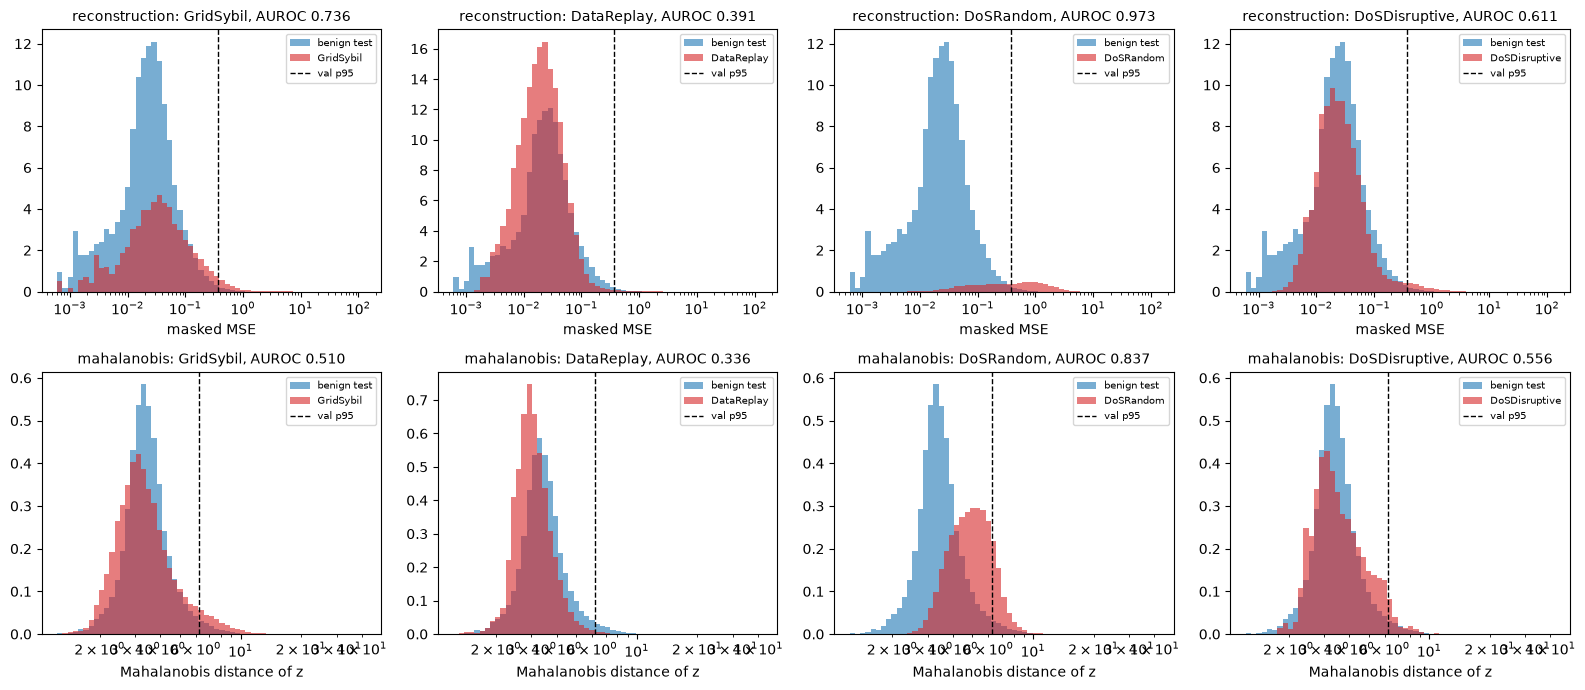

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for r, name in enumerate(SCORES):
    allv = np.concatenate([scored[n][(name, "window")] for n in EVAL_SPLITS])
    bins = np.logspace(np.log10(max(allv.min(), 1e-5)), np.log10(allv.max()), 60)
    for c, (attack, short) in enumerate(ATTACKS.items()):
        ax = axes[r, c]
        ax.hist(scored["test"][(name, "window")], bins=bins, alpha=0.6, density=True, label="benign test")
        ax.hist(scored[attack][(name, "window")], bins=bins, alpha=0.6, density=True, label=short, color="tab:red")
        ax.axvline(thresholds[(name, "window")]["p95"], color="black", ls="--", lw=1, label="val p95")
        y, s = pair(attack, (name, "window"))
        ax.set_xscale("log"); ax.set_title(f"{name}: {short}, AUROC {roc_auc_score(y, s):.3f}", fontsize=10)
        ax.set_xlabel("masked MSE" if name == "reconstruction" else "Mahalanobis distance of z")
        ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

Reconstruction error vs real messages per window (median per length), benign test and each attack: short windows are
where most DataReplay / DoS windows sit (F11).

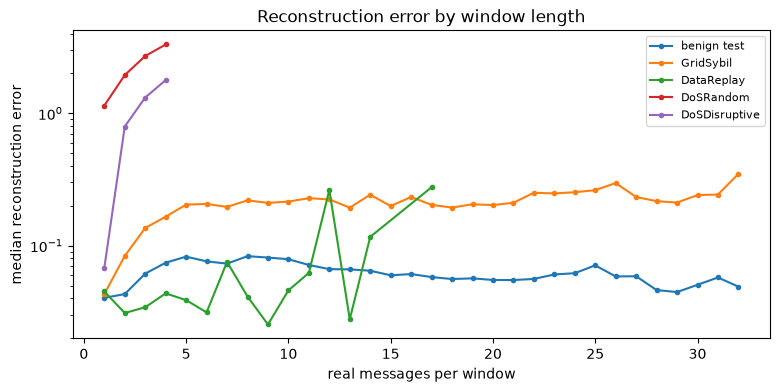

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
for n, lab in [("test", "benign test"), *ATTACKS.items()]:
    df = pd.DataFrame({"n": scored[n]["n_messages"], "e": scored[n][("reconstruction", "window")]})
    g = df.groupby("n").e.median()
    ax.plot(g.index, g.values, marker=".", label=lab)
ax.set_yscale("log"); ax.set_xlabel("real messages per window"); ax.set_ylabel("median reconstruction error")
ax.legend(fontsize=8); ax.set_title("Reconstruction error by window length")
plt.show()

Mean per-feature reconstruction error by class on the test windows, and the per-feature AUROC of each attack vs benign test.

In [18]:
ef = {n: scored[n]["error_feature"] for n in EVAL_SPLITS}
tab = pd.DataFrame({("mean error", "benign"): ef["test"].mean(0)}, index=FEATURES)
for attack, short in ATTACKS.items():
    tab[("mean error", short)] = ef[attack].mean(0)
for attack, short in ATTACKS.items():
    y = np.r_[np.zeros(len(ef["test"]), int), np.ones(len(ef[attack]), int)]
    e = np.r_[ef["test"], ef[attack]]
    tab[("AUROC", short)] = [roc_auc_score(y, e[:, j]) for j in range(e.shape[1])]
tab.columns = pd.MultiIndex.from_tuples(tab.columns)
tab.round(3)

mean error                                               \
                  benign GridSybil DataReplay DoSRandom DoSDisruptive   
claimed_pos_x      0.014     0.195      0.046     0.533         0.198   
claimed_pos_y      0.011     0.176      0.044     0.569         0.174   
rx_pos_x           0.015     0.114      0.067     0.412         0.271   
rx_pos_y           0.013     0.096      0.051     0.369         0.170   
claimed_vel_x      0.086     0.193      0.051     3.356         0.126   
claimed_vel_y      0.073     0.233      0.059     2.472         0.128   
rx_vel_x           0.120     0.313      0.060     0.206         0.110   
rx_vel_y           0.098     0.277      0.077     0.154         0.119   
claimed_acl_x      0.373     0.996      0.086     0.608         0.224   
claimed_acl_y      0.334     0.776      0.097     0.708         0.229   
range              0.039     1.125      0.477     8.600         3.023   
bearing            0.105     0.307      0.115     0.588         0.224   
log_dtau           0.130     3.563      0.003     0.129         0.085   

                  AUROC                                     
              GridSybil DataReplay DoSRandom DoSDisruptive  
claimed_pos_x     0.683      0.590     0.929         0.749  
claimed_pos_y     0.735      0.639     0.919         0.783  
rx_pos_x          0.633      0.559     0.852         0.684  
rx_pos_y          0.674      0.614     0.862         0.767  
claimed_vel_x     0.612      0.415     0.898         0.493  
claimed_vel_y     0.660      0.434     0.852         0.475  
rx_vel_x          0.607      0.411     0.558         0.462  
rx_vel_y          0.658      0.390     0.527         0.448  
claimed_acl_x     0.620      0.268     0.618         0.357  
claimed_acl_y     0.644      0.238     0.661         0.317  
range             0.768      0.644     0.945         0.801  
bearing           0.683      0.494     0.787         0.562  
log_dtau          0.694      0.458     0.416         0.448

The windows with at least 4 real rows per split: how many, and the median normalised log-Δτ of their real rows (benign train mean / std scale).

In [19]:
rows = {}
for n, lab in [("test", "benign test"), *ATTACKS.items()]:
    d = test_data[n]
    sel = d.n_messages >= 4
    rows[lab] = {"windows >= 4 rows": int(sel.sum()), "share": round(float(sel.mean()), 4),
                 "median log_dtau (real rows)": float(np.median(d.x[sel][d.mask[sel]][:, FEATURES.index("log_dtau")]))}
pd.DataFrame(rows).T.round(3)

,windows >= 4 rows,share,median log_dtau (real rows)
benign test,51773.0,0.861,-0.134
GridSybil,22365.0,0.796,-0.134
DataReplay,3883.0,0.051,-0.134
DoSRandom,523.0,0.003,12.135
DoSDisruptive,524.0,0.003,12.135


2-D PCA of the latent z (fitted on the benign test z; 4,000 windows per class; inspection only).

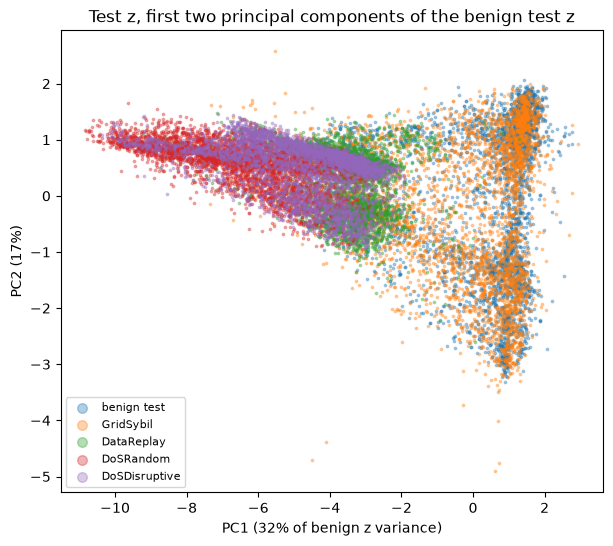

In [20]:
rng = np.random.default_rng(0)
pca = PCA(2, random_state=0).fit(scored["test"]["z"])
fig, ax = plt.subplots(figsize=(7, 6))
for n, lab in [("test", "benign test"), *ATTACKS.items()]:
    z = scored[n]["z"]
    zz = pca.transform(z[rng.choice(len(z), size=min(4000, len(z)), replace=False)])
    ax.scatter(zz[:, 0], zz[:, 1], s=3, alpha=0.35, label=lab)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of benign z variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=4, fontsize=8); ax.set_title("Test z, first two principal components of the benign test z")
plt.show()

## 6. Context (not a fair comparison)

Earlier autoencoders in `task/`, on different inputs (benign + GridSybil only, T = 48, other splits), GridSybil vs benign
window AUROC on their own test splits:

- unsupervised ConvAutoencoders trained on benign + GridSybil as "normal" (`task/autoencoder`, `task/autoencoder_overlap`):
  reconstruction AUROC **0.484**;
- supervised autoencoder with a classifier head (`task/autoencoder_st`, GridSybil labels in training): AUROC **0.929**
  (GridSybil only, says nothing about unseen attacks).

Different data, window length, split and training signal: these numbers frame the result, they do not rank the models.

In [21]:
ctx = res[(res.level == "window") & (res.score != "length only (reference)")].pivot_table(
    index="score", columns="attack", values="AUROC", sort=False)[list(ATTACKS.values())]
ctx.loc["task/autoencoder(_overlap), T48, unsupervised (context)", "GridSybil"] = 0.484
ctx.loc["task/autoencoder_st, T48, supervised (context)", "GridSybil"] = 0.929
ctx.round(3)

attack,GridSybil,DataReplay,DoSRandom,DoSDisruptive
score,,,,
reconstruction,0.736,0.391,0.973,0.611
mahalanobis,0.510,0.336,0.837,0.556
"task/autoencoder(_overlap), T48, unsupervised (context)",0.484,NaN,NaN,NaN
"task/autoencoder_st, T48, supervised (context)",0.929,NaN,NaN,NaN


The numbers the analysis below refers to.

In [22]:
results = {"run": RUN.name, "params": summary["params"], "best_epoch": summary["best_epoch"],
           "best_val_loss": round(summary["best_val_loss"], 5), "epochs_run": summary["epochs_run"],
           "stop_reason": summary["stop_reason"], "lr_changes": len(summary["lr_changes"])}
for _, r in res.iterrows():
    keys = [k for k in ("AUROC", "AUROC (>= 4 rows)", "PR-AUC", "chance", "recall p95", "benign FPR p95", "recall p99", "benign FPR p99")
            if k in r and pd.notna(r[k])]
    results[f"{r.attack}/{r.score}/{r.level}"] = {k: round(float(r[k]), 3) for k in keys}
results

{'run': 'seed0',
 'params': 63293,
 'best_epoch': 151,
 'best_val_loss': 0.10503,
 'epochs_run': 161,
 'stop_reason': 'early_stopping',
 'lr_changes': 7,
 'GridSybil/reconstruction/window': {'AUROC': 0.736,
  'AUROC (>= 4 rows)': 0.778,
  'PR-AUC': 0.629,
  'chance': 0.318,
  'recall p95': 0.298,
  'benign FPR p95': 0.048,
  'recall p99': 0.179,
  'benign FPR p99': 0.009},
 'GridSybil/reconstruction/track max': {'AUROC': 0.713,
  'PR-AUC': 0.596,
  'chance': 0.325,
  'recall p95': 0.256,
  'benign FPR p95': 0.048,
  'recall p99': 0.134,
  'benign FPR p99': 0.009},
 'GridSybil/reconstruction/track mean': {'AUROC': 0.721,
  'PR-AUC': 0.611,
  'chance': 0.325,
  'recall p95': 0.276,
  'benign FPR p95': 0.049,
  'recall p99': 0.147,
  'benign FPR p99': 0.009},
 'GridSybil/mahalanobis/window': {'AUROC': 0.51,
  'AUROC (>= 4 rows)': 0.54,
  'PR-AUC': 0.394,
  'chance': 0.318,
  'recall p95': 0.127,
  'benign FPR p95': 0.048,
  'recall p99': 0.048,
  'benign FPR p99': 0.01},
 'GridSybil/mahal

## 7. Analysis

Numbers from the outputs above (run `seed0`, one seed, no confidence intervals). Not a thesis detection result: the
TimesNet plan is unchanged; this is the one-class baseline the professor asked for (RULE 1: reported as produced).

- **Training worked as a reconstruction model of benign traffic.** 63,293 parameters. Benign val masked MSE fell from
  0.196 (epoch 1) to 0.115 (epoch 50) and **0.1050** (best, epoch 151); early stopping (min_delta 1e-4 relative,
  patience 10) ended the run at epoch 161 after 7 LR halvings (1e-3 to 7.8e-6, the first after epoch 98), 19.4 min on
  MPS. Train and val end close (0.1005 vs 0.1050). The mean gradient norm (pre-clip) went from 0.27 to its minimum
  0.15 at epoch 99 and then sat at about 0.19 while the LR halved: mini-batch noise, not an unfinished slope.
  Acceleration is the hardest feature to rebuild (val MSE 0.37 / 0.33), positions the easiest (0.011-0.015).
- **Calibration transfers from val to test.** Thresholds are benign-val quantiles; on the benign test windows the
  false-positive rate is 0.048 at val p95 and 0.009 at val p99 (window level; track level 0.048-0.049 / 0.009-0.012).
- **GridSybil: the reconstruction error detects part of it.** Window AUROC **0.736** (PR-AUC 0.629, chance 0.318),
  0.778 on the windows with at least 4 real rows, against 0.559 for window length alone; at val p95 recall **0.298**
  (p99: 0.179). Per track it does not improve (max 0.713, mean 0.721). The ghosts are rebuilt worst on log-Δτ (mean
  error 3.56 vs 0.13 benign) and range (1.13 vs 0.04); per-feature AUROC is highest for range (0.768). Mahalanobis on z
  is at chance (0.510 window, 0.488 / 0.491 track).
- **DataReplay is not detected; the scores point the wrong way.** Reconstruction AUROC **0.391**, Mahalanobis 0.336
  (0.349 / 0.295 on the 3,883 windows with at least 4 rows); recall at val p95 0.046 / 0.008. Replayed messages are
  real trajectories of other cars, so a model of normal motion finds them normal, and 94.9% of these windows hold 1-3
  messages, which the model rebuilds easily. Window length alone gives 0.952. Flipping the sign would be a direction
  chosen on test labels, so it is not a result.
- **DoSRandom is detected, but mostly by values a 1-message window already shows.** Reconstruction AUROC **0.973**
  (recall 0.880 at val p95), length alone 0.967. The error sits in claimed velocity (3.36 / 2.47 vs 0.09 / 0.07 benign)
  and range (8.6 vs 0.04): the random claimed values are out of the benign range even in a single message. Mahalanobis
  0.837.
- **DoSDisruptive is barely detected:** reconstruction **0.611** (recall 0.292), Mahalanobis 0.556, length alone 0.967.
  On the 524 windows with at least 4 rows (0.26% of the split) both scores reach 0.999-1.000, but these windows have
  normalised log-Δτ around 12 (benign about −0.13): their message timing, not their motion, is what is off.
- **F11 limits what this model can judge.** 94.9% of DataReplay and 99.7% of DoS windows hold 1-3 real messages, so a
  trajectory autoencoder sees almost no trajectory; window length alone beats it on DataReplay and DoSDisruptive and
  matches it on DoSRandom. Only on GridSybil (20.4% short windows) does the model add something beyond length.
- **Mahalanobis on z is weak everywhere** (window AUROC 0.34-0.84): z (16 numbers) summarises the shape of a window, and the
  attacks show up in the per-feature reconstruction (range, log-Δτ, claimed velocity) rather than as an unusual z.
- **Caveats.** One seed. F14: GridSybil_0709 is a re-simulation of the 0709 traffic, so near-copies of 0709 cars can
  straddle train and test in this split (not measured here; the 1416 group is not affected). Benign traffic appears
  once per attack family (F1, about 4×), so benign test windows are not independent. Track ids hold the true sender
  (F13). Context only (section 6): the T48 autoencoders trained on benign + GridSybil as "normal" scored 0.484 on
  GridSybil, the supervised T48 autoencoder 0.929 with GridSybil labels; different data, window length, split and
  training signal.